In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df= pd.read_csv("/content/healthcare_preprocessed (1).csv")

In [3]:
df.head()

,Name,Age,Gender,Blood_Type,Medical_Condition,Admission_Date,Doctor,Hospital,Insurance_Provider,Billing_Amount,Room Number,Admission_Type,Discharge_Date,Medication,Test_Results,Length_of_Stay,Age_Group,Admission_Urgency
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal,2,19-30,Urgent
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive,6,61-75,Emergency
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal,15,76+,Emergency
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal,30,19-30,Elective
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal,20,31-45,Urgent


In [4]:
print("Number od rows:", df.shape[0])
print("Number of column:",df.shape[1])

Number od rows: 54966
Number of column: 18


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54966 entries, 0 to 54965
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Name                54966 non-null  object 
 1   Age                 54966 non-null  int64  
 2   Gender              54966 non-null  object 
 3   Blood_Type          54966 non-null  object 
 4   Medical_Condition   54966 non-null  object 
 5   Admission_Date      54966 non-null  object 
 6   Doctor              54966 non-null  object 
 7   Hospital            54966 non-null  object 
 8   Insurance_Provider  54966 non-null  object 
 9   Billing_Amount      54966 non-null  float64
 10  Room Number         54966 non-null  int64  
 11  Admission_Type      54966 non-null  object 
 12  Discharge_Date      54966 non-null  object 
 13  Medication          54966 non-null  object 
 14  Test_Results        54966 non-null  object 
 15  Length_of_Stay      54966 non-null  int64  
 16  Age_

In [6]:
print(df.columns.tolist())

['Name', 'Age', 'Gender', 'Blood_Type', 'Medical_Condition', 'Admission_Date', 'Doctor', 'Hospital', 'Insurance_Provider', 'Billing_Amount', 'Room Number', 'Admission_Type', 'Discharge_Date', 'Medication', 'Test_Results', 'Length_of_Stay', 'Age_Group', 'Admission_Urgency']


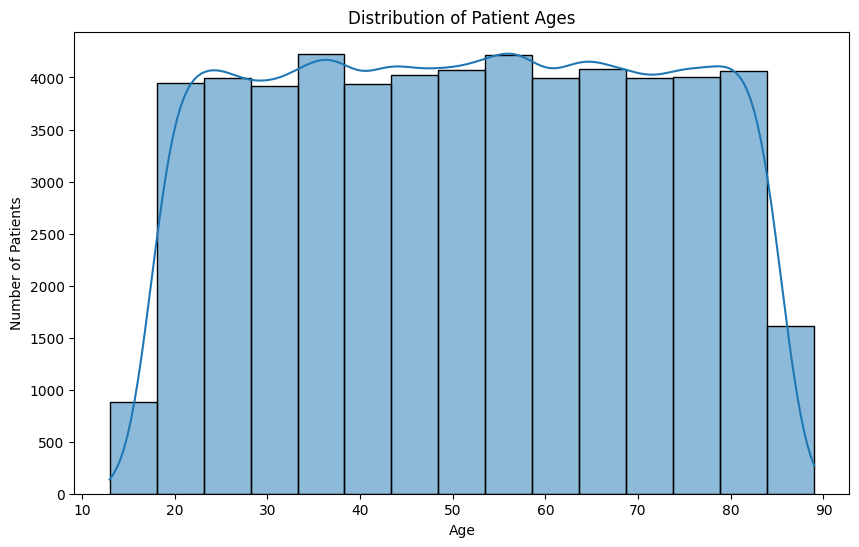

In [7]:
plt.figure(figsize=(10,6))

sns.histplot(
    data=df,
    x="Age",
    bins=15,
    kde=True
)
plt.title("Distribution of Patient Ages")
plt.xlabel("Age")
plt.ylabel("Number of Patients")
plt.show()

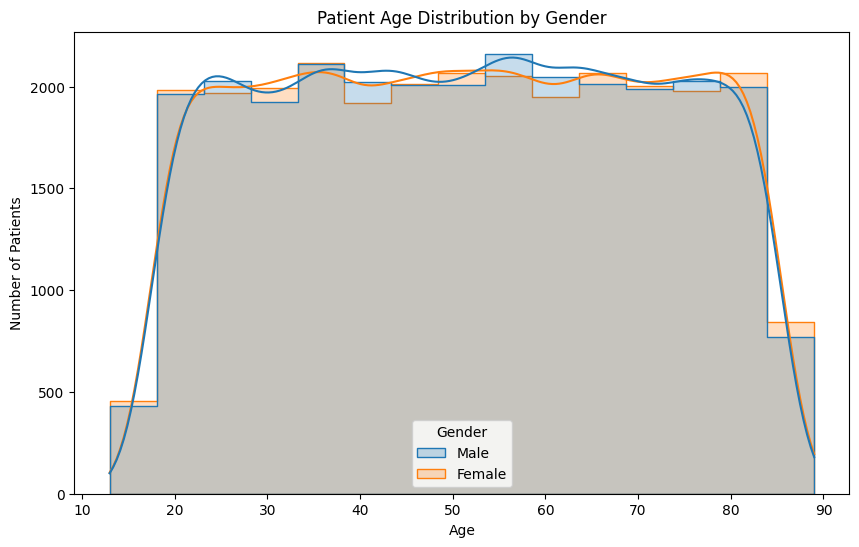

In [8]:
plt.figure(figsize=(10,6))

sns.histplot(
    data=df,
    x="Age",
    hue="Gender",
    bins=15,
    kde=True,
    element="step"
)
plt.title("Patient Age Distribution by Gender")
plt.xlabel("Age")
plt.ylabel("Number of Patients")
plt.show()

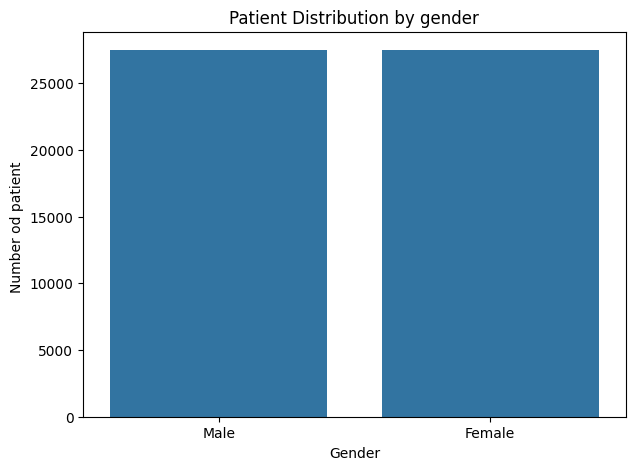

In [9]:
gender_counts=df["Gender"].value_counts()

plt.figure(figsize=(7,5))
sns.barplot(x=gender_counts.index, y=gender_counts.values)
plt.title("Patient Distribution by gender")
plt.xlabel("Gender")
plt.ylabel("Number od patient ")

plt.show()

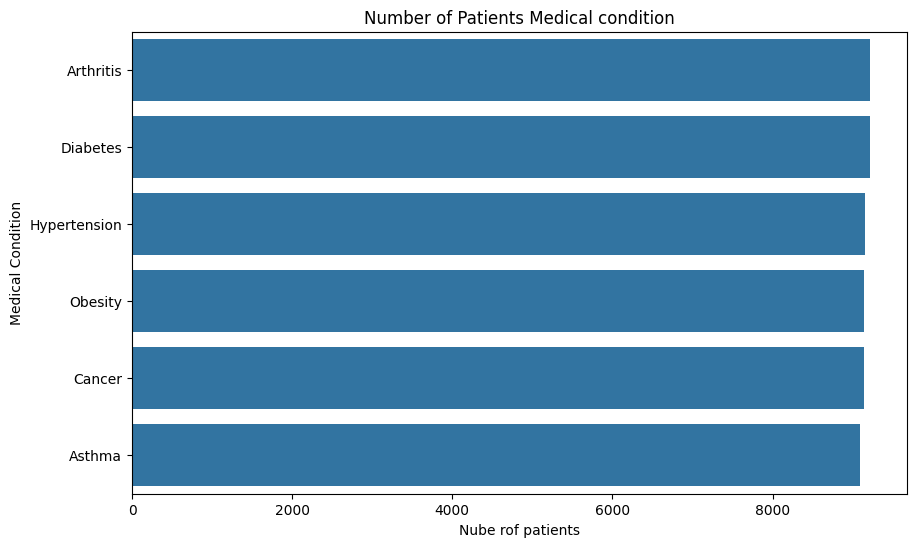

In [10]:
condition_counts=df["Medical_Condition"].value_counts()

plt.figure(figsize=(10,6))
sns.barplot(x=condition_counts.values, y=condition_counts.index)
plt.title("Number of Patients Medical condition")
plt.xlabel("Nube rof patients")
plt.ylabel("Medical Condition")

plt.show()

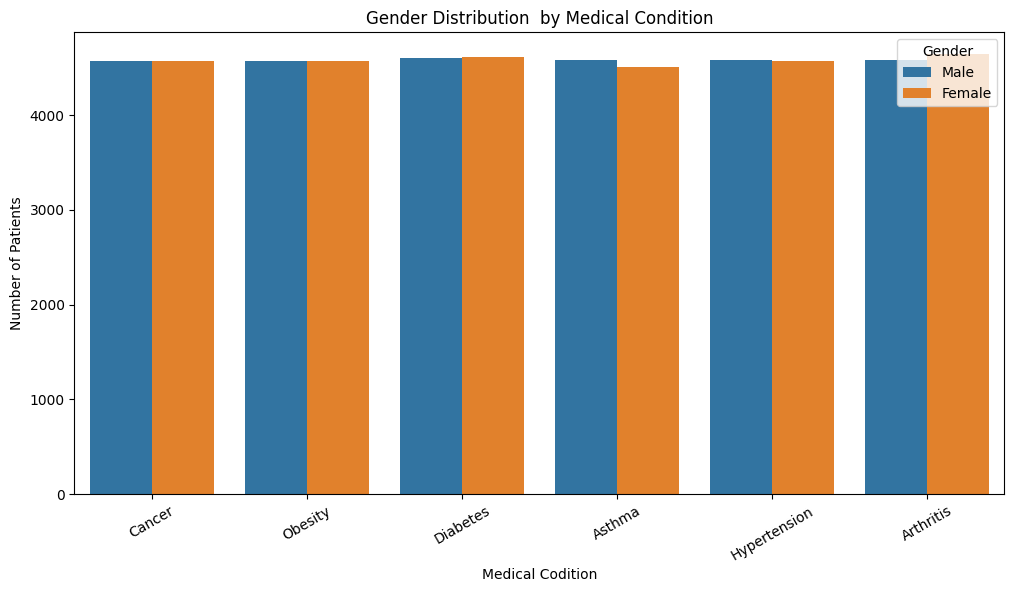

In [11]:
plt.figure(figsize=(12,6))
sns.countplot(
    data=df,
    x="Medical_Condition",
    hue="Gender",
)
plt.title("Gender Distribution  by Medical Condition")
plt.xlabel("Medical Codition")
plt.ylabel("Number of Patients")
plt.xticks(rotation=30)
plt.show()

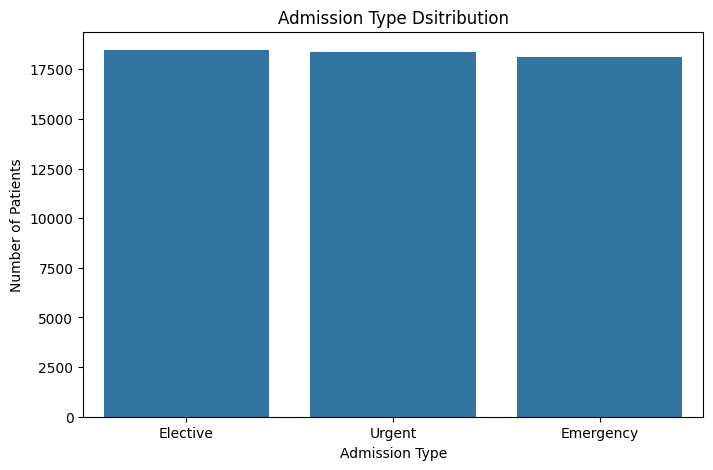

In [12]:
admission_counts=df["Admission_Type"].value_counts()
plt.figure(figsize=(8,5))
sns.barplot(x=admission_counts.index, y=admission_counts.values)
plt.title("Admission Type Dsitribution")
plt.xlabel("Admission Type")
plt.ylabel("Number of Patients")
plt.show()

In [13]:
admission_condition=pd.crosstab(
    df["Medical_Condition"],
    df["Admission_Type"]
)
print(admission_condition)

Admission_Type     Elective  Emergency  Urgent
Medical_Condition                             
Arthritis              3062       3073    3083
Asthma                 3069       2978    3048
Cancer                 3114       2988    3038
Diabetes               3031       2988    3197
Hypertension           3182       2975    2994
Obesity                3015       3100    3031


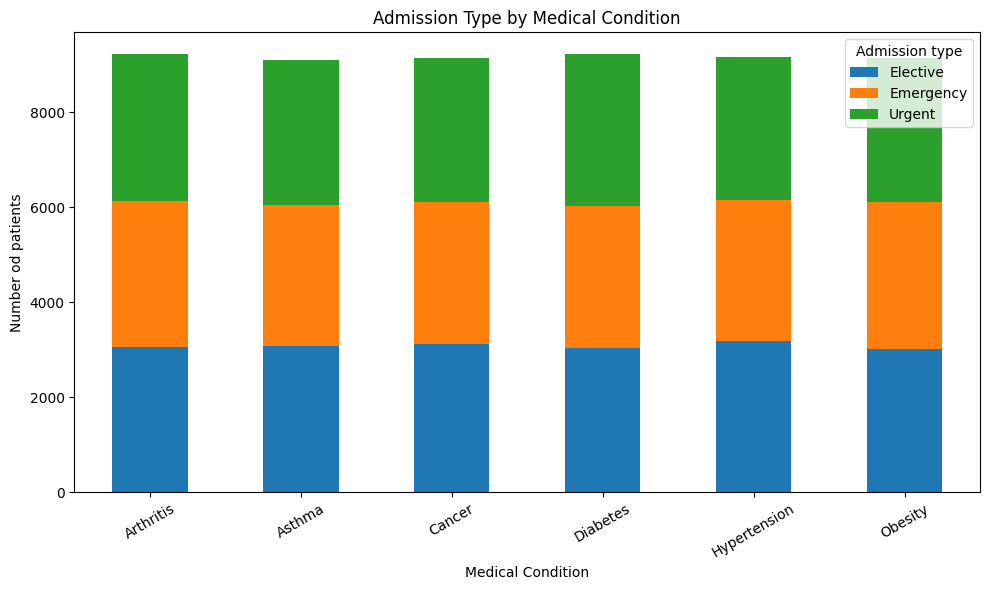

In [14]:
admission_condition.plot(
    kind="bar",
    stacked=True,
    figsize=(10,6)
)
plt.title("Admission Type by Medical Condition")
plt.xlabel("Medical Condition")
plt.ylabel("Number od patients")


plt.xticks(rotation=30)
plt.legend(title="Admission type")

plt.tight_layout()
plt.show()

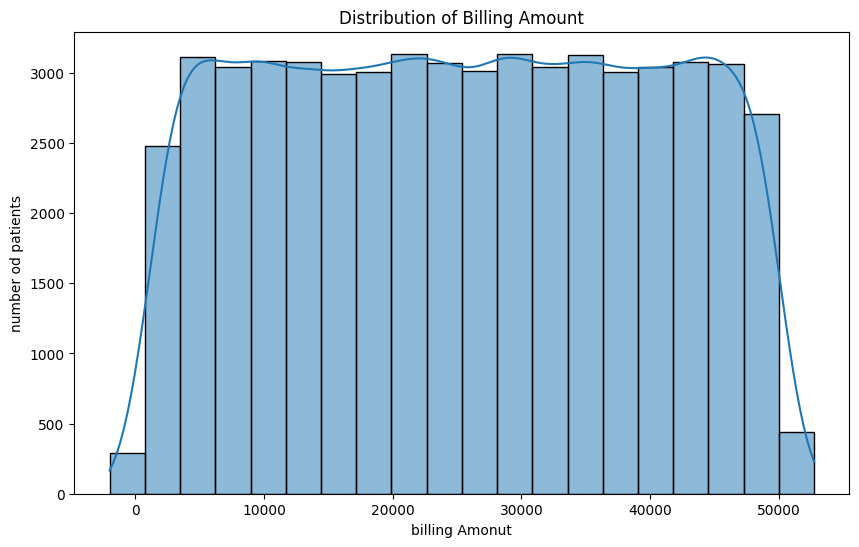

In [15]:
plt.figure(figsize=(10,6))
sns.histplot(
    data=df,
    x="Billing_Amount",
    bins=20,
    kde=True

)
plt.title("Distribution of Billing Amount")
plt.xlabel("billing Amonut")
plt.ylabel("number od patients")

plt.show()

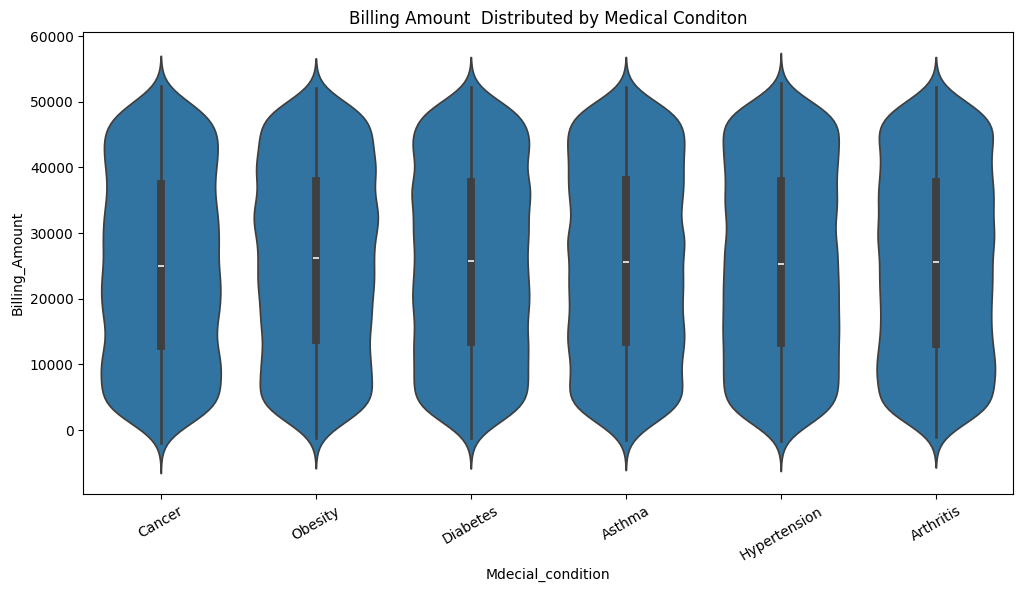

In [16]:
plt.figure(figsize=(12,6))
sns.violinplot(
    data=df,
    x="Medical_Condition",
    y="Billing_Amount"
)

plt.title("Billing Amount  Distributed by Medical Conditon")
plt.xlabel("Mdecial_condition")
plt.ylabel("Billing_Amount")

plt.xticks(rotation=30)
plt.show()

In [17]:
avg_condition_billing=(
    df.groupby("Medical_Condition")["Billing_Amount"]
    .mean()
    .sort_values(ascending=False)
)
print(avg_condition_billing)

Medical_Condition
Obesity         25804.361902
Diabetes        25660.478635
Asthma          25633.461696
Arthritis       25511.783246
Hypertension    25503.058720
Cancer          25152.322947
Name: Billing_Amount, dtype: float64


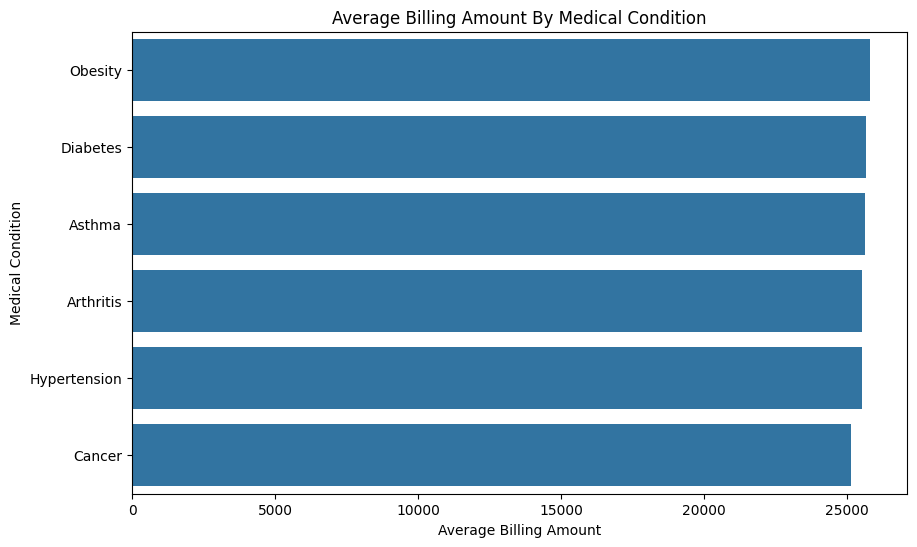

In [18]:
plt.figure(figsize=(10,6))
sns.barplot(x=avg_condition_billing.values, y=avg_condition_billing.index)
plt.title("Average Billing Amount By Medical Condition")
plt.xlabel("Average Billing Amount")
plt.ylabel("Medical Condition")
plt.show()


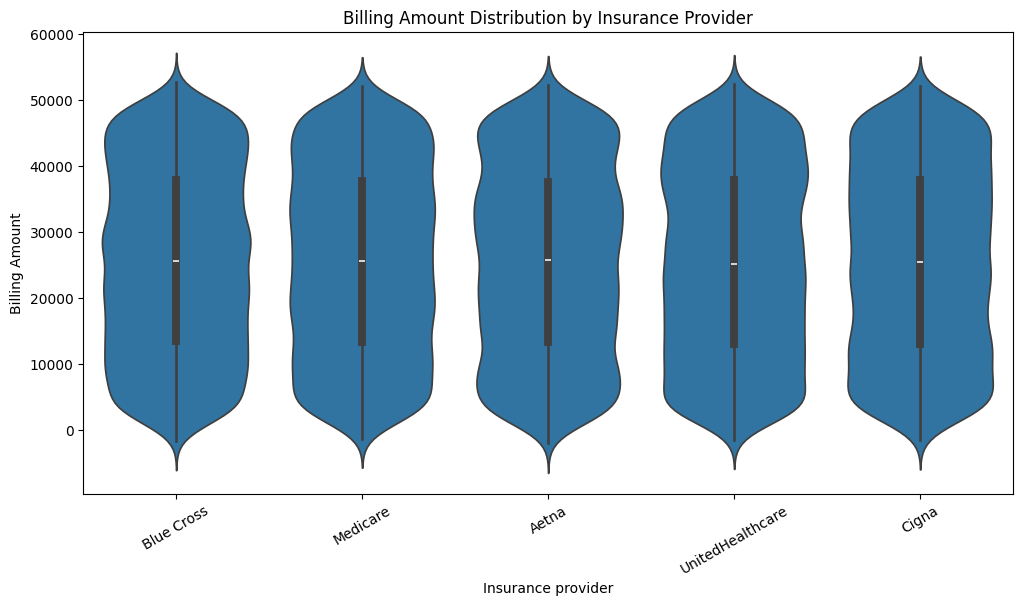

In [19]:
plt.figure(figsize=(12,6))
sns.violinplot(
    data=df,
    x="Insurance_Provider",
    y="Billing_Amount"
)
plt.title("Billing Amount Distribution by Insurance Provider")
plt.xlabel("Insurance provider")
plt.ylabel("Billing Amount")

plt.xticks(rotation=30)

plt.show()